# Model v1 vs v2: evaluation

Compares **v1** (word TF-IDF + random forest, the original model) with **v2** (TF-IDF on letter chunks + logistic regression, now used by the app), with the **ELECTRA-small** transformer experiment alongside.
The numbers come from `uv run sweet-truth model evaluate`, which writes `reports/`. This notebook reads them, explains how they are judged, shows the confusion matrices and the mistakes, and lets you try the models.

Longer write-ups: [EVALUATION.md](../reports/EVALUATION.md) · [APPROACH.md](../src/sweet_truth/training/APPROACH.md) · [DATASET.md](../src/sweet_truth/training/DATASET.md)

## 1. How performance is judged

Each ingredient is either a **sweetener** (positive) or **other** (negative):

| | Predicted sweetener | Predicted other | |
| --- | --- | --- | --- |
| **Actual sweetener** | True positive (TP) | False negative (FN), *Type II error* | **Sensitivity** = TP / (TP + FN) |
| **Actual other** | False positive (FP), *Type I error* | True negative (TN) | **Specificity** = TN / (TN + FP) |
| | **Precision** = TP / (TP + FP) | **Negative predictive value** = TN / (TN + FN) | **Accuracy** = (TP + TN) / all |

- **Sensitivity (recall) matters most.** A missed sweetener (false negative) is the costly error; precision guards against false alarms.
- **Accuracy alone misleads.** Only about 13% of ingredients are sweeteners, so "never a sweetener" would already be 87% accurate.
- **The test set flatters every model.** All of its ingredients also appear in training. The **unseen-ingredient** folds and the **challenge** set are where the models really differ.

## 2. v1 vs v2 in one table

| | v1 | v2 |
| --- | --- | --- |
| Trained on | whole lists | single ingredients (as the app uses it) |
| Input | brackets deleted, lemmatised words | brackets kept, text as written |
| Features | TF-IDF on whole words | TF-IDF on letter chunks of 1–6 characters |
| Classifier | random forest (451 trees) | logistic regression |
| Size | 7.2 MB | 0.2 MB |
| Explains itself | no | yes, which letter chunks made it say "sweetener" |

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from sweet_truth.training.evaluate import REPORTS_DIR, SETS

names = ["v1", "v2", "electra-small"]
reports = {n: json.loads((REPORTS_DIR / f"{n}.json").read_text()) for n in names if (REPORTS_DIR / f"{n}.json").exists()}
ablation = json.loads((REPORTS_DIR / "ablation.json").read_text())
list(reports)

['v1', 'v2', 'electra-small']

## 3. Measures on every set

In [2]:
measures = ["recall", "specificity", "precision", "npv", "accuracy", "f1"]
rows = []
for key, title in SETS.items():
    for name, report in reports.items():
        m = report["sets"].get(key)
        if m:
            rows.append({"set": title, "model": name, **{k: m[k] for k in measures}})
table = pd.DataFrame(rows).rename(columns={"recall": "sensitivity", "npv": "neg. pred. value"}).set_index(["set", "model"])
table.style.format(precision=2).background_gradient(cmap="Purples", vmin=0.3, vmax=1.0)

## 4. Confusion matrices

v1 vs v2 on every set. Violet cells are correct, amber cells are errors.

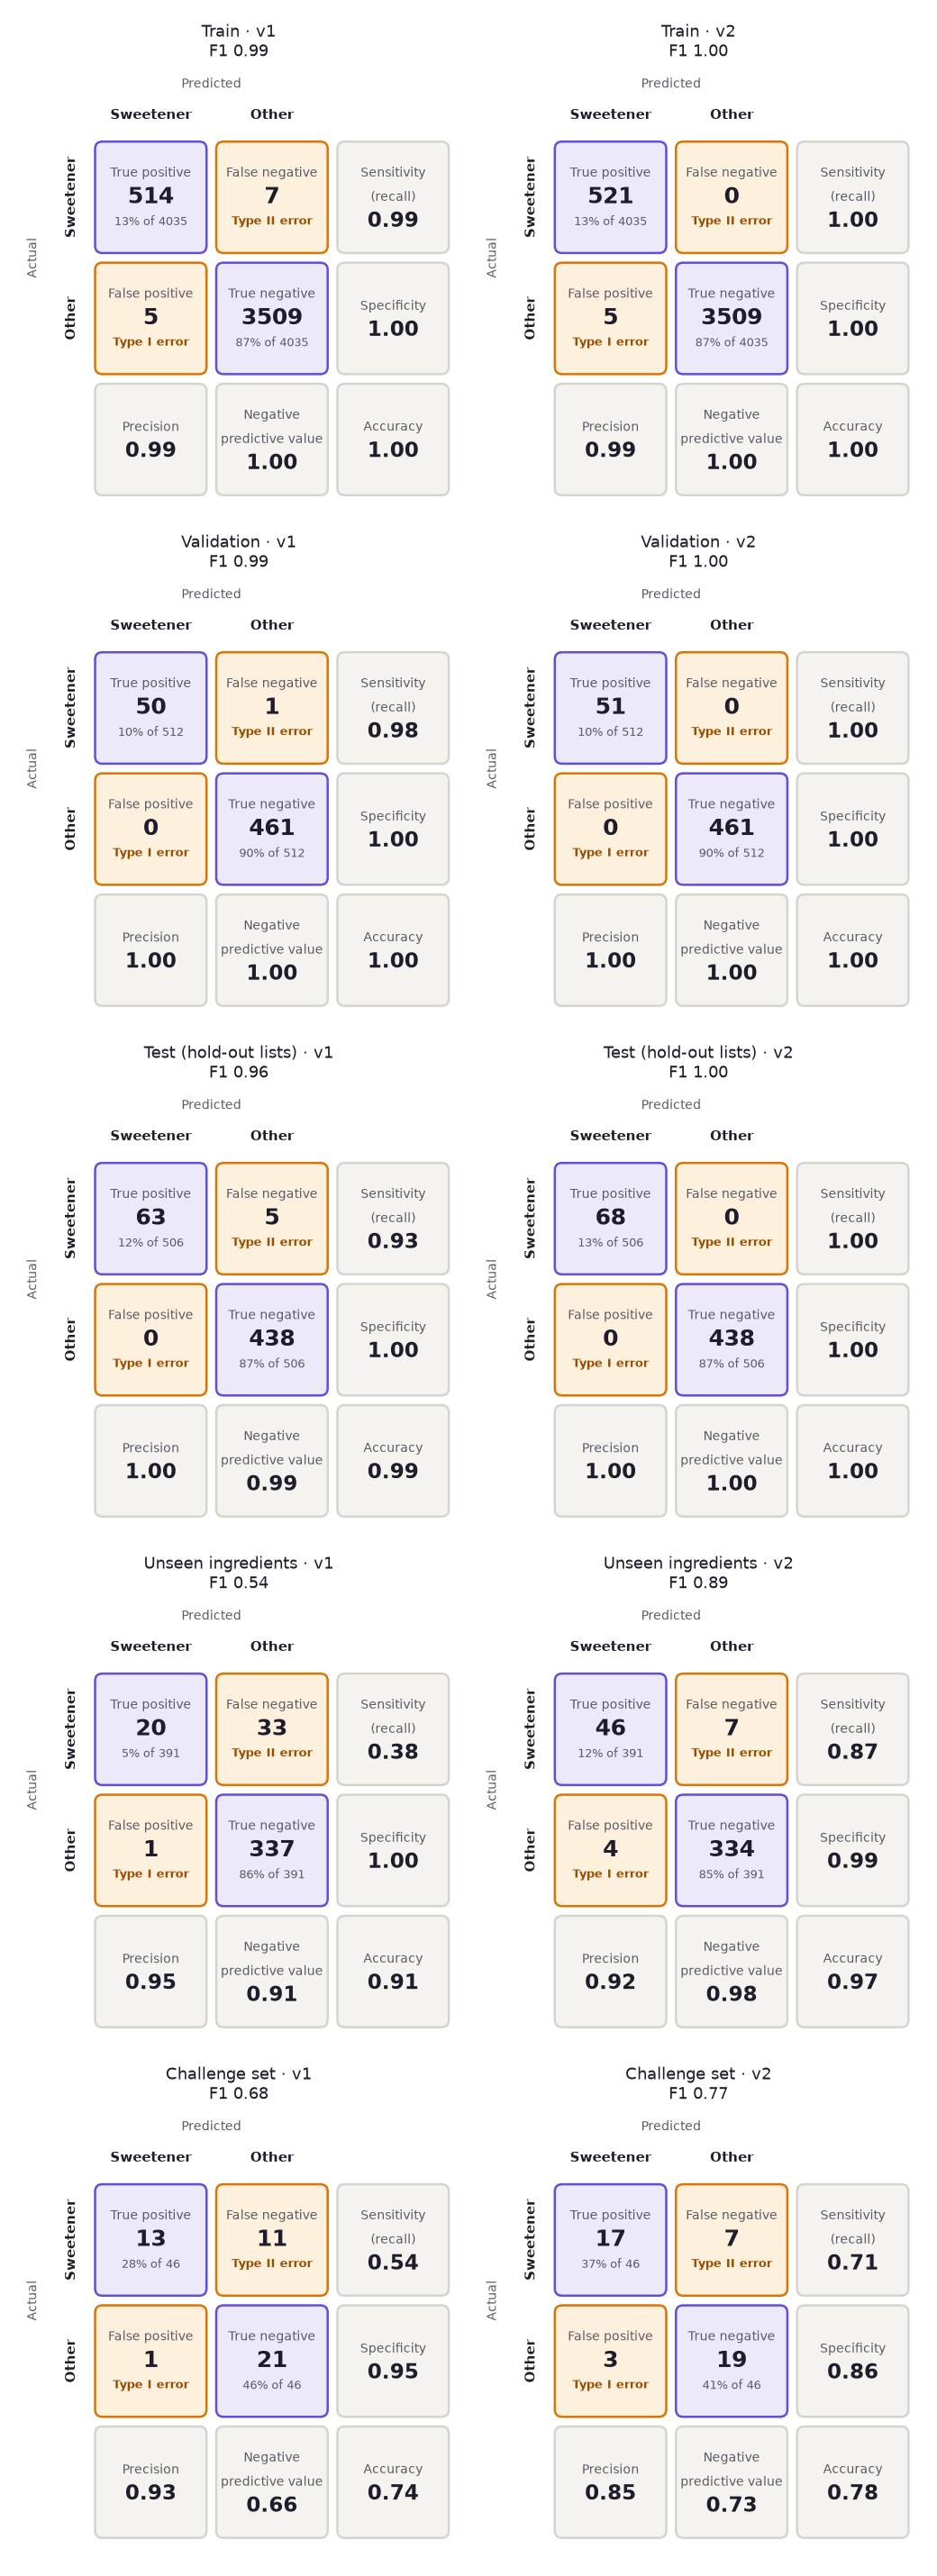

In [3]:
display(Image(filename=REPORTS_DIR / "figures" / "confusion_overview.png", width=620))

The two sets that separate the models, with the transformer experiment alongside:

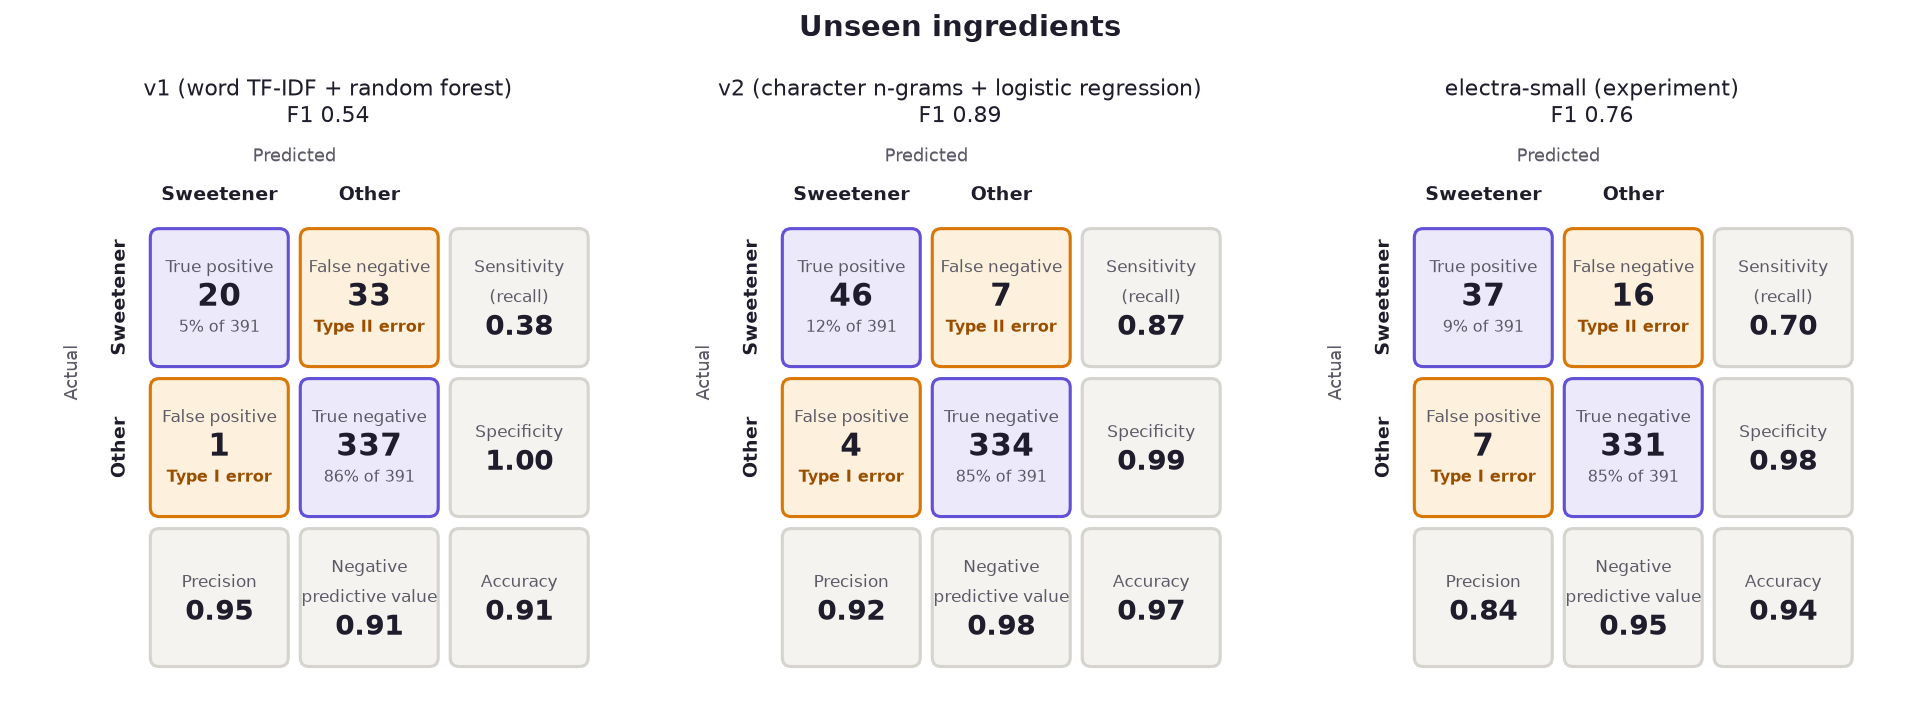

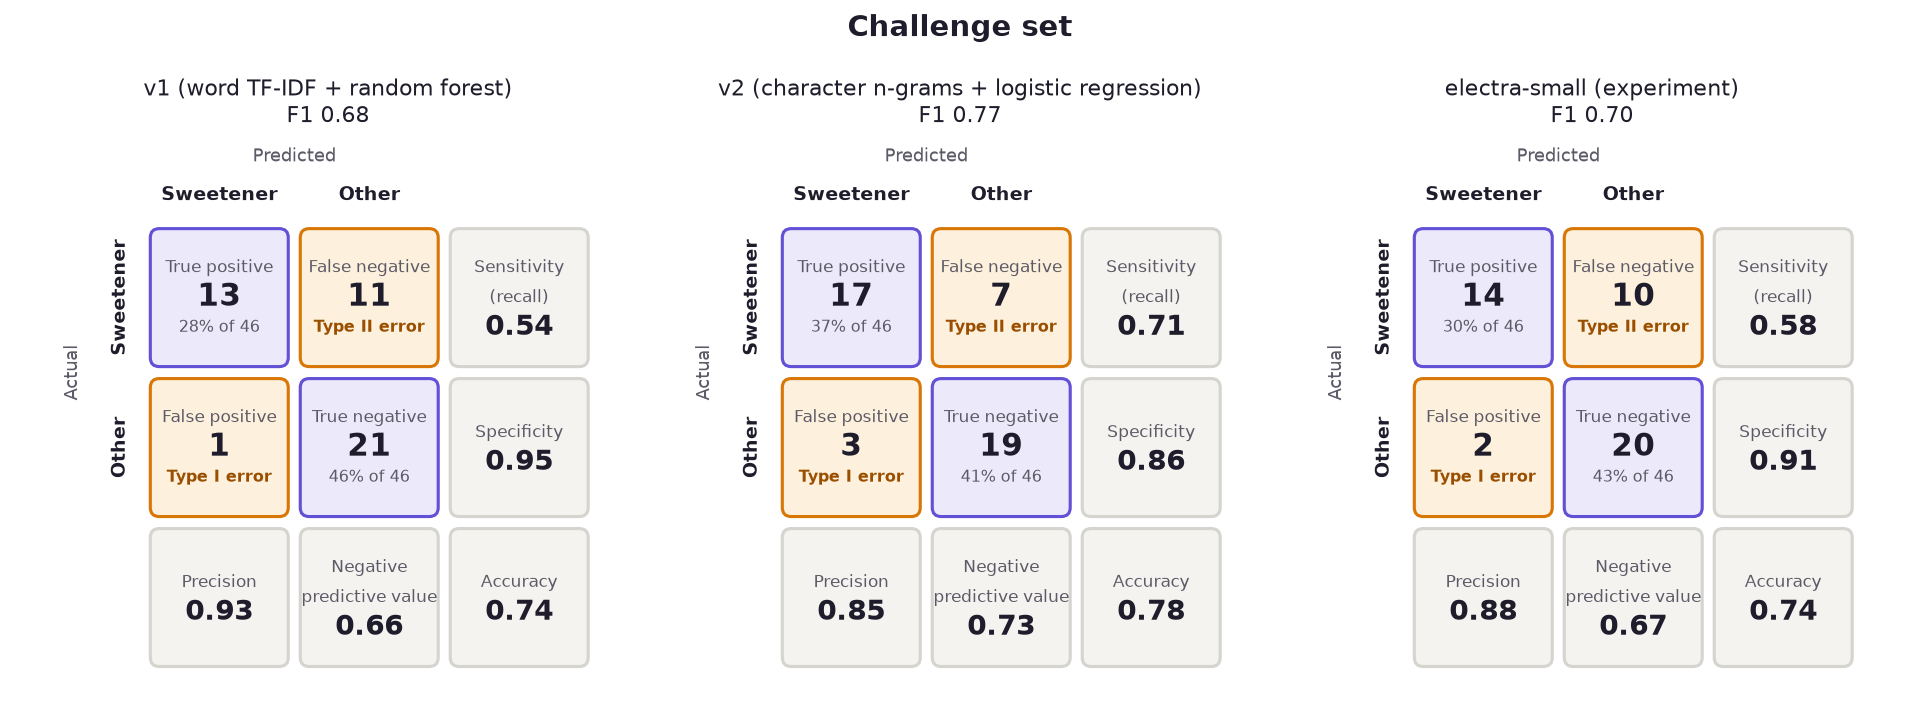

In [4]:
for key in ("unseen", "challenge"):
    display(Image(filename=REPORTS_DIR / "figures" / f"confusion_{key}.png", width=900))

## 5. Which change matters: features or classifier?

v1 and v2 differ in two things. All four combinations, trained the same way on single ingredients, scored on unseen ingredients:

In [5]:
pd.DataFrame([
    {"features": r["features"], "classifier": r["classifier"],
     "unseen recall": r["unseen"]["recall"], "unseen precision": r["unseen"]["precision"],
     "unseen F1": r["unseen"]["f1"], "challenge accuracy": r["challenge"]["accuracy"]}
    for r in ablation
]).style.format(precision=2)

,features,classifier,unseen recall,unseen precision,unseen F1,challenge accuracy
0,words,forest,0.38,0.95,0.54,0.74
1,words,logistic,0.47,0.93,0.62,0.74
2,chars,forest,0.55,0.94,0.69,0.83
3,chars,logistic,0.87,0.92,0.89,0.78


Letter chunks matter most, and logistic regression adds a large further gain on top of them. On the small challenge set, letter chunks with a random forest scores slightly higher (38 vs 36 of 46 correct). The choice was made on the larger unseen-ingredient folds, as decided beforehand.

## 6. Mistakes

### Challenge set: probability of *sweetener* from each model

In [6]:
challenge = pd.DataFrame({
    name: {p["ingredient"]: p["probability"] for p in r["challenge_predictions"]} for name, r in reports.items()
})
labels = {p["ingredient"]: p["label"] for p in reports["v1"]["challenge_predictions"]}
challenge.insert(0, "label", pd.Series(labels))
wrong = challenge[(challenge["v2"] >= 0.5) != (challenge["label"] == 1)]
print(f"v2 gets {len(wrong)} of {len(challenge)} wrong:")
wrong.style.format(precision=2).background_gradient(cmap="Purples", vmin=0, vmax=1, subset=names)

v2 gets 10 of 46 wrong:


,label,v1,v2,electra-small
allulose,1,0.02,0.21,0.00
treacle,1,0.02,0.04,0.00
monk fruit extract,1,0.24,0.25,0.00
thaumatin,1,0.02,0.01,0.00
neohesperidin dihydrochalcone,1,0.02,0.02,0.00
sodium cyclamate,1,0.05,0.01,0.00
rebaudioside A,1,0.02,0.05,0.00
ethyl maltol,0,0.16,0.88,1.00
glucose oxidase,0,0.70,0.94,1.00
agar,0,0.02,0.92,0.00


v2 misses sweeteners whose names give no clue (thaumatin, cyclamate, neohesperidin) and flags look-alikes (ethyl maltol, glucose oxidase). A curated list of sweeteners and their INS / E-numbers is the planned fix for the first group.

### Sample photos

In [7]:
pd.DataFrame([
    {"model": name, "photo": image, **{k: ", ".join(v) for k, v in result.items()}}
    for name, r in reports.items() for image, result in (r["photos"] or {}).items()
    if result["missed"] or result["extra"]
])

,model,photo,found,missed,extra
0,electra-small,toothpaste.jpg,sorbitol,sodium saccharin,"physician. MRP Rs. (incl,, of all taxes)"


## 7. Why did v2 say "sweetener"?

The app shows, under each flagged ingredient, the parts of its name that pushed v2 towards "sweetener": each letter chunk's TF-IDF value times the model's weight for it, with overlapping chunks merged.

In [8]:
from sweet_truth.config import Settings
from sweet_truth.text import classify_ingredients, load_resources

app_model = load_resources(Settings(model="v2"), with_ocr=False)

def check(ingredient_list: str) -> pd.DataFrame:
    result = classify_ingredients(ingredient_list, app_model)
    return pd.DataFrame([
        {"ingredient": i.text, "sweetener": i.is_sweetener, "confidence": round(i.confidence, 2), "because of": ", ".join(i.reasons)}
        for i in result.items
    ])

check("Wheat flour, Isomaltulose, Coconut sugar (12%), Sorbitol, Sweetener (INS 955), Ethyl maltol, Salt and Water")

,ingredient,sweetener,confidence,because of
0,Wheat flour,False,1.00,
1,Isomaltulose,True,0.98,"isomalt-, -ose"
2,Coconut sugar (12%),True,0.78,sugar
3,Sorbitol,True,0.99,sorbitol
4,Sweetener (INS 955),True,0.95,sweetener
5,Ethyl maltol,True,0.89,maltol
6,Salt,False,0.98,
7,Water,False,0.99,


## 8. Try it yourself

Compare all three models on any ingredient list (v1 and v2 are refitted on the 800 training lists here, so they match the reported numbers).

In [9]:
from sweet_truth.classifiers import SpacyTextcat
from sweet_truth.text import load_nlp
from sweet_truth.training import baselines
from sweet_truth.training.data import examples_of, load_lists, notebook_split
from sweet_truth.training.train import MODELS_DIR

nlp = load_nlp()
split = notebook_split(load_lists())
models = {
    "v1": baselines.V1AsApp(baselines.train_v1_on_lists(split.train, nlp), nlp),
    "v2": baselines.fit_v2(examples_of(split.train)),
}
if (MODELS_DIR / "electra-small" / "model-best").is_dir():
    models["electra-small"] = SpacyTextcat(MODELS_DIR / "electra-small" / "model-best")

def compare(ingredient_list: str) -> pd.DataFrame:
    return pd.DataFrame({name: dict(model.classify_text(ingredient_list)) for name, model in models.items()}).round(2)

compare("Wheat flour, Allulose, Brown rice syrup, Sodium bicarbonate, Ethyl maltol, Sweetener (INS 955), Salt")

/Users/bhawakshipunia/data_science/portfolio_projects/sweet_truth/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,v1,v2,electra-small
Wheat flour,0.20,0.00,0.0
Allulose,0.02,0.21,0.0
Brown rice syrup,0.86,0.91,0.0
Sodium bicarbonate,0.05,0.00,0.0
Ethyl maltol,0.16,0.88,1.0
Sweetener,0.63,NaN,NaN
Salt,0.13,0.03,0.0
Sweetener (INS 955),NaN,0.94,1.0
